In [1]:
from pathlib import Path
import sys
import json
import os
import matplotlib.pyplot as plt

# Directory paths
LMMS_EVAL_DIR = Path.home() / "multimodal_finetuned_representations/evals/llava-1.5-7b/lmms_eval"
PLOTTING_DIR = Path.home() / "multimodal_finetuned_representations/plotting"

# Reference scores from LLaVA-1.5-7B paper (MODEL_ZOO.md)
REFERENCE_SCORES = {
    'vqav2': 78.5,
    'gqa': 62.0,
    'vizwiz': 50.0,
    'scienceqa': 66.8,
    'textvqa': 58.2,
    'pope': 85.9,
    'mme': 1510.7,
    'mmbench': 64.3,
    'mmbench_cn': 58.3,
    'seedbench': 58.6,  # SEEDBench_IMG
    'llava_in_the_wild': 65.4,
    'mmvet': 31.1
}

# Model naming and colors
basename = "Llava1.5-7B"
NAMES_MAPPING = {
    basename: "full",
    f"{basename}-0-16": "0-16",
    f"{basename}-16-32": "16-32",
    f"{basename}-frozen": "frozen_llm",
    "finetuned": "FM",
    "pretrained": "PM"
}

COLOR_SCHEME = {
    'full': '#08519c',      # Dark blue - all layers fine-tuned
    '0-16': '#6baed6',      # Medium blue - early-upper layers
    '16-32': '#9ecae1',     # Light blue - upper layers only
    'frozen_llm': '#006d2c', # Dark green - frozen projector, all LLM layers trained
    'PM': 'black',
    'FM': 'red',
}

# Function to load results
def load_results(benchmark_dir):
    results_file = next((f for f in os.listdir(benchmark_dir) if 'results' in f and f.endswith('.jsonl')), None)
    if results_file:
        with open(benchmark_dir / results_file, 'r') as f:
            return [json.loads(line) for line in f]
    return None

# Function to parse data
def parse_data(results, score_key):
    models_collection = set()
    for score in results:
        exp_name = score['experiment_name'].split('/')[0]
        if 'finetuned' not in exp_name:
            models_collection.add(exp_name)

    data = {exp: {} for exp in models_collection}
    checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
    for collection in models_collection:
        for experiment in results:
            exp_name = experiment['experiment_name'].split('/')[0]
            if exp_name == collection:
                step = experiment['experiment_name'].split('-')[-1]
                if step in checkpoint_steps:
                    data[collection][int(step)] = experiment[score_key]

    # Handle finetuned and pretrained
    finetuned_exp = next((exp for exp in results if exp['experiment_name'].endswith('finetuned')), None)
    pretrained_exp = next((exp for exp in results if exp['experiment_name'].endswith('pretrained')), None)
    if finetuned_exp:
        data['finetuned'] = finetuned_exp[score_key]
    if pretrained_exp:
        data['pretrained'] = pretrained_exp[score_key]
    
    return data, models_collection

# Function to plot
def plot_benchmark(benchmark_name, data, models_collection, score_key, ylim, reference_score=None):
    fig, ax = plt.subplots(figsize=(8, 6))
    for collection in models_collection:
        label = NAMES_MAPPING.get(collection, collection)
        color = COLOR_SCHEME.get(label, "#000000")
        if data[collection]:
            steps, scores = zip(*sorted(data[collection].items()))
            ax.plot(steps, scores, label=label, color=color, marker="o", linestyle="--")

    if "finetuned" in data:
        label = NAMES_MAPPING.get("finetuned", "finetuned")
        color = COLOR_SCHEME.get(label, "red")
        ax.scatter(11000, data["finetuned"], label=label, color=color, marker="o")

    if "pretrained" in data:
        label = NAMES_MAPPING.get("pretrained", "pretrained")
        color = COLOR_SCHEME.get(label, "black")
        ax.scatter(0, data["pretrained"], label=label, color=color, marker="o")

    # Scale reference score based on ylim
    if reference_score is not None:
        if ylim[1] == 1:
            ref = reference_score / 100
        else:
            ref = reference_score
        ax.axhline(y=ref, color='purple', linestyle='--', linewidth=2, label='Paper')

    ax.set_ylim(ylim)
    ax.set_xlabel("Training Steps")
    ax.set_ylabel(f"{benchmark_name.upper()} {score_key.replace(',', '').replace('_', ' ').title()}")
    ax.set_title(f"{benchmark_name.upper()} Scores Across Model Variants")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

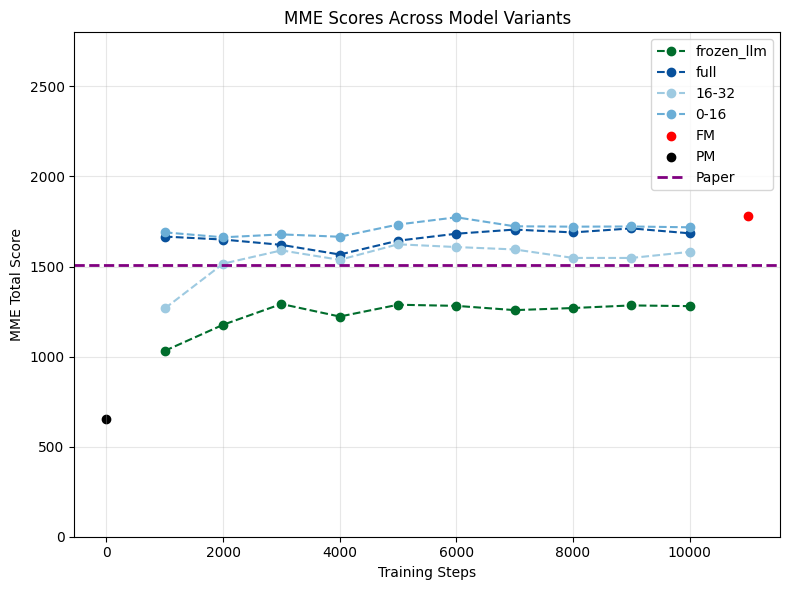

In [2]:
# MME - Special case with total score
benchmark = 'mme'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    # Calculate total scores
    data = {exp: {} for exp in ['Llava1.5-7B']}  # Assuming similar
    models_collection = set()
    for score in results:
        exp_name = score['experiment_name'].split('/')[0]
        if 'finetuned' not in exp_name:
            models_collection.add(exp_name)
    data = {exp: {} for exp in models_collection}
    checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
    for collection in models_collection:
        for experiment in results:
            exp_name = experiment['experiment_name'].split('/')[0]
            if exp_name == collection:
                step = experiment['experiment_name'].split('-')[-1]
                if step in checkpoint_steps:
                    perception = experiment['mme_perception_score,none']
                    cognition = experiment['mme_cognition_score,none']
                    data[collection][int(step)] = perception + cognition

    finetuned_exp = next((exp for exp in results if exp['experiment_name'].endswith('finetuned')), None)
    pretrained_exp = next((exp for exp in results if exp['experiment_name'].endswith('pretrained')), None)
    if finetuned_exp:
        perception = finetuned_exp['mme_perception_score,none']
        cognition = finetuned_exp['mme_cognition_score,none']
        data['finetuned'] = perception + cognition
    if pretrained_exp:
        perception = pretrained_exp['mme_perception_score,none']
        cognition = pretrained_exp['mme_cognition_score,none']
        data['pretrained'] = perception + cognition

    plot_benchmark(benchmark, data, models_collection, 'total_score', (0, 2800), REFERENCE_SCORES.get('mme'))

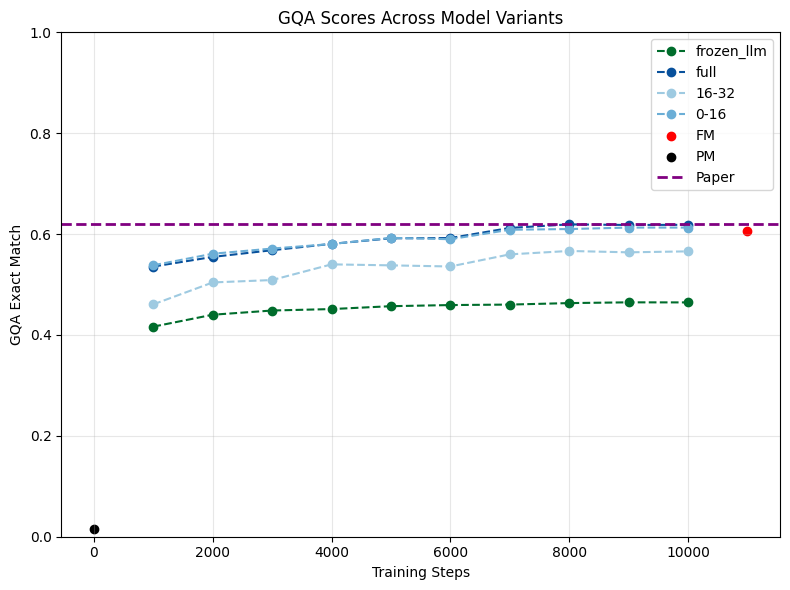

In [3]:
# GQA
benchmark = 'gqa'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'exact_match,none')
    plot_benchmark(benchmark, data, models_collection, 'exact_match', (0, 1), REFERENCE_SCORES.get('gqa'))

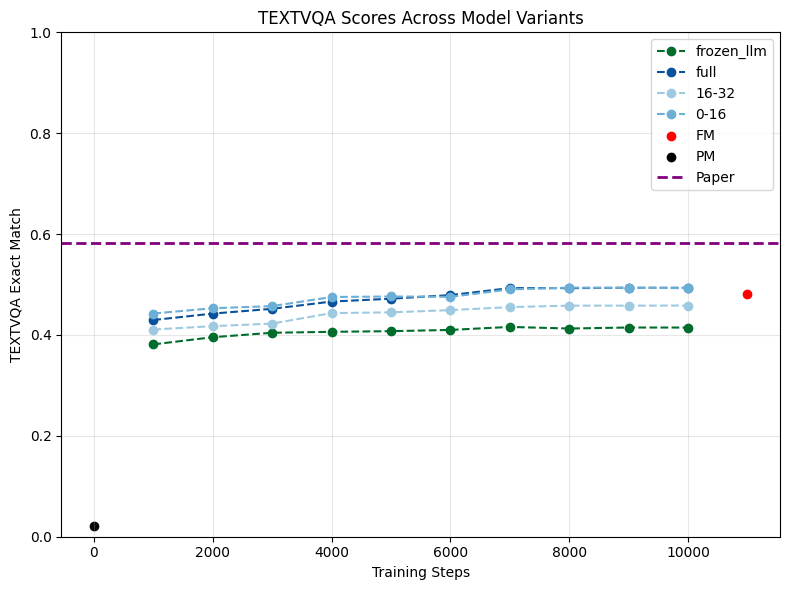

In [4]:
# TextVQA
benchmark = 'textvqa_val'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'exact_match,none')
    plot_benchmark(benchmark.replace('_val', ''), data, models_collection, 'exact_match', (0, 1), REFERENCE_SCORES.get('textvqa'))

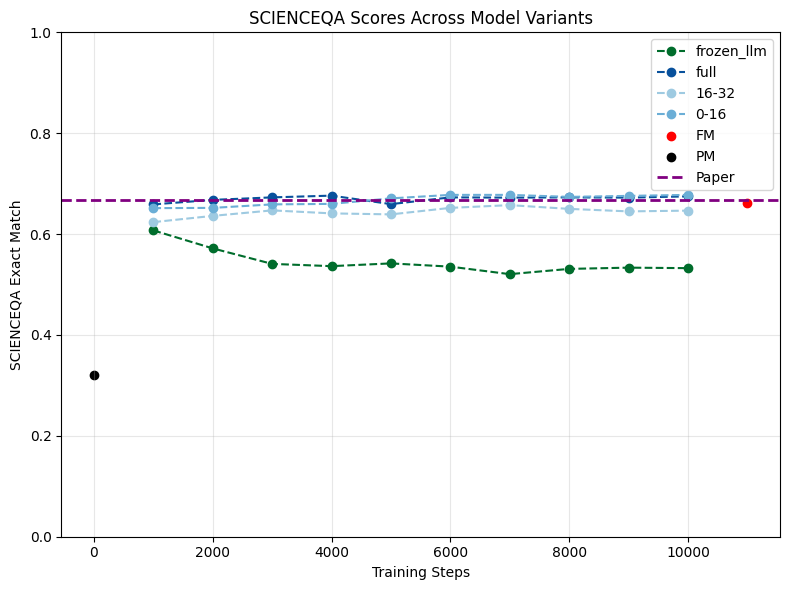

In [5]:
# ScienceQA
benchmark = 'scienceqa_img'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'exact_match,none')
    plot_benchmark(benchmark.replace('_img', ''), data, models_collection, 'exact_match', (0, 1), REFERENCE_SCORES.get('scienceqa'))

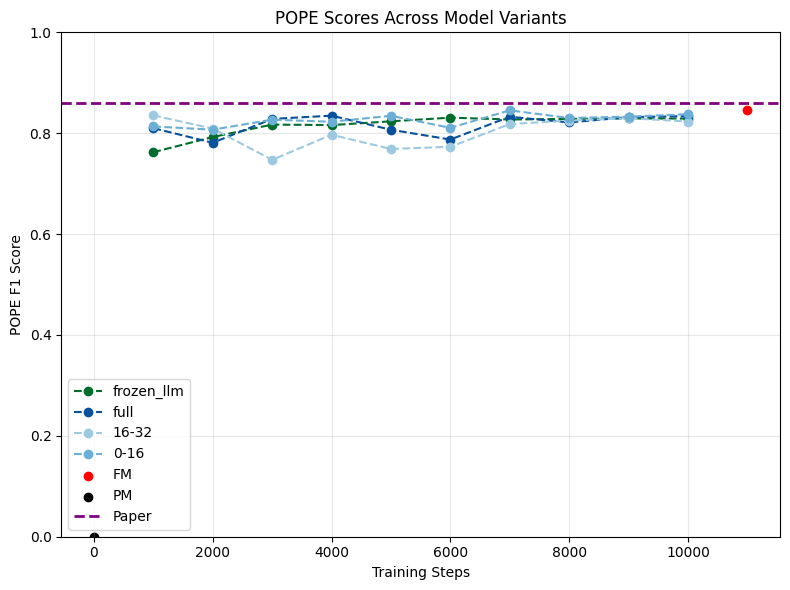

In [6]:
# POPE
benchmark = 'pope'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'pope_f1_score,none')
    plot_benchmark(benchmark, data, models_collection, 'f1_score', (0, 1), REFERENCE_SCORES.get('pope'))

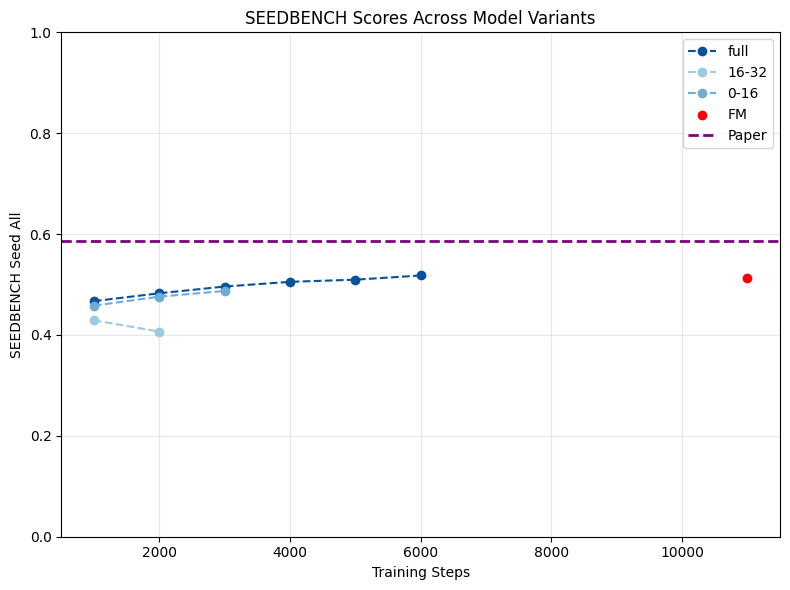

In [7]:
# SEEDBench
benchmark = 'seedbench'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'seed_all,none')
    plot_benchmark(benchmark, data, models_collection, 'seed_all', (0, 1), REFERENCE_SCORES.get('seedbench'))

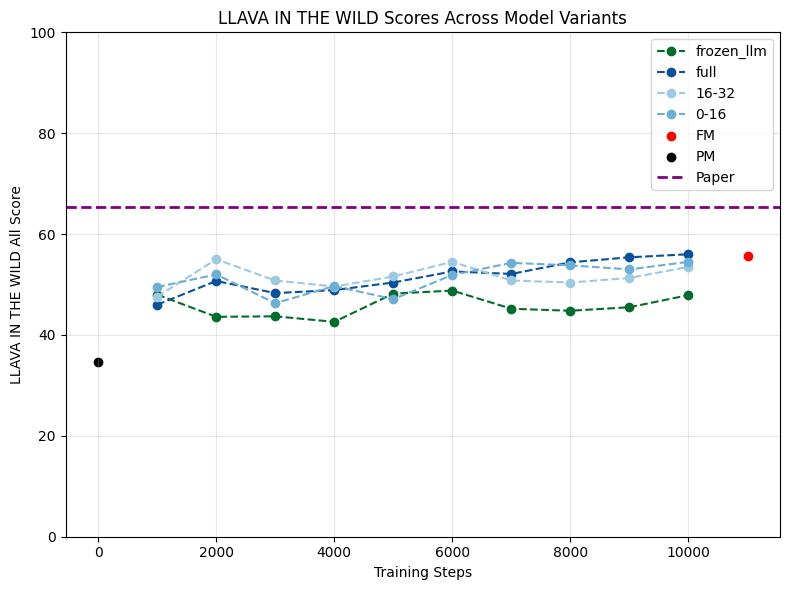

In [8]:
# LLaVA in the Wild
benchmark = 'llava_in_the_wild'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'gpt_eval_llava_all,none')
    plot_benchmark(benchmark.replace('_', ' ').title(), data, models_collection, 'all_score', (0, 100), REFERENCE_SCORES.get('llava_in_the_wild'))

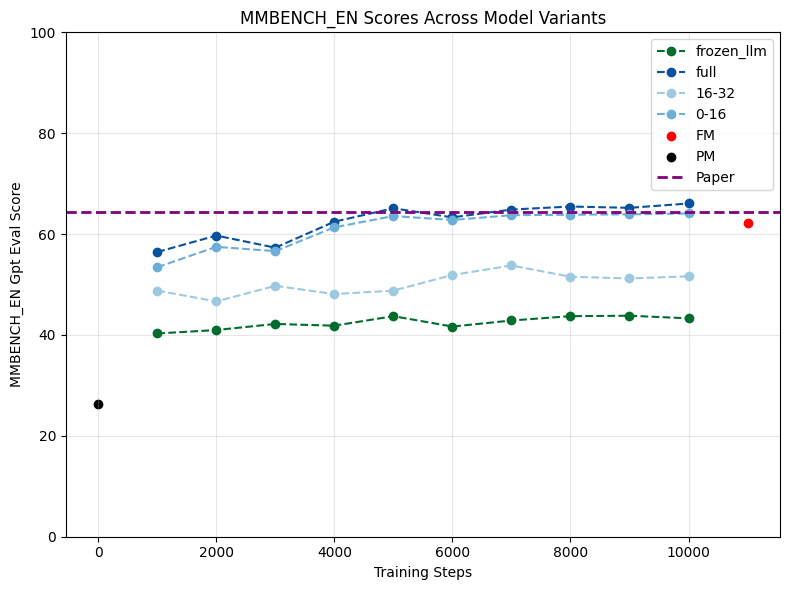

In [9]:
# MMBench EN
benchmark = 'mmbench_en_dev'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'gpt_eval_score,none')
    plot_benchmark('MMBench_EN', data, models_collection, 'gpt_eval_score', (0, 100), REFERENCE_SCORES.get('mmbench'))

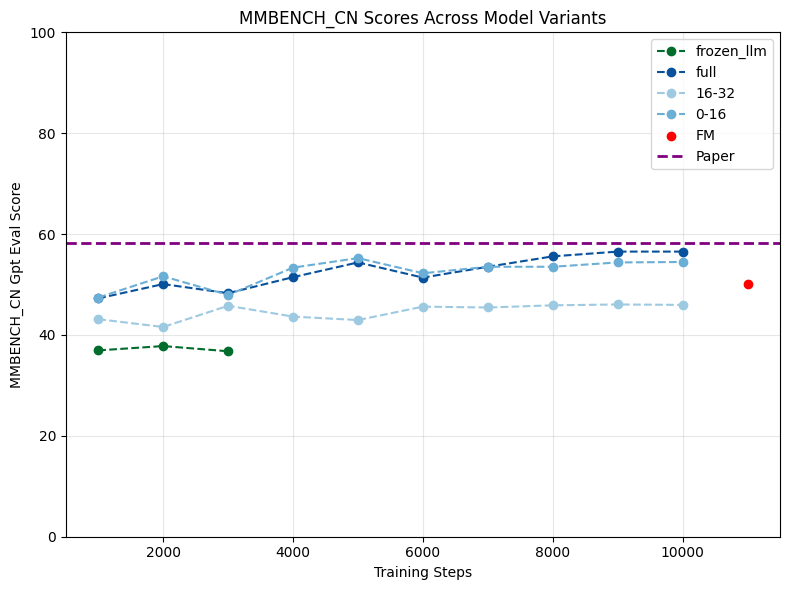

In [10]:
# MMBench CN
benchmark = 'mmbench_cn_dev'
results = load_results(LMMS_EVAL_DIR / benchmark)
if results:
    data, models_collection = parse_data(results, 'gpt_eval_score,none')
    plot_benchmark('MMBench_CN', data, models_collection, 'gpt_eval_score', (0, 100), REFERENCE_SCORES.get('mmbench_cn'))

# Radar Plot: Model Comparison Across All Benchmarks

This section creates a radar (spider) plot showing:
- Left subplot: Reference scores (LLaVA-1.5-7B paper, Finetuned, Pretrained)
- Right subplot: Training variants (full, frozen_llm, 0-16, 16-32) with their best checkpoint scores

In [11]:
import numpy as np
from math import pi

# Define benchmarks and their normalization factors
BENCHMARKS = {
    'MME': {'dir': 'mme', 'key': 'total', 'max_val': 2800, 'abbrev': 'MME'},
    'GQA': {'dir': 'gqa', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'GQA'},
    'TextVQA': {'dir': 'textvqa_val', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'TextVQA'},
    'ScienceQA': {'dir': 'scienceqa_img', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'SQA'},
    'POPE': {'dir': 'pope', 'key': 'pope_f1_score,none', 'max_val': 1, 'abbrev': 'POPE'},
    'SEEDBench': {'dir': 'seedbench', 'key': 'seed_all,none', 'max_val': 1, 'abbrev': 'SEED'},
    'LLaVA-Wild': {'dir': 'llava_in_the_wild', 'key': 'gpt_eval_llava_all,none', 'max_val': 100, 'abbrev': 'LLaVA-W'},
    'MMBench': {'dir': 'mmbench_en_dev', 'key': 'gpt_eval_score,none', 'max_val': 100, 'abbrev': 'MMB-EN'},
    'MMBench-CN': {'dir': 'mmbench_cn_dev', 'key': 'gpt_eval_score,none', 'max_val': 100, 'abbrev': 'MMB-CN'}
}

# Reference scores normalized
REFERENCE_NORMALIZED = {
    'MME': 1510.7 / 2800,
    'GQA': 62.0 / 100,
    'TextVQA': 58.2 / 100,
    'ScienceQA': 66.8 / 100,
    'POPE': 85.9 / 100,
    'SEEDBench': 58.6 / 100,
    'LLaVA-Wild': 65.4 / 100,
    'MMBench': 64.3 / 100,
    'MMBench-CN': 58.3 / 100
}

def extract_max_scores():
    """Extract maximum score and corresponding checkpoint for each model on each benchmark"""
    model_scores = {}
    
    for bench_name, bench_info in BENCHMARKS.items():
        results = load_results(LMMS_EVAL_DIR / bench_info['dir'])
        if not results:
            continue
            
        # Process MME separately (sum perception + cognition)
        if bench_name == 'MME':
            models_collection = set()
            for score in results:
                exp_name = score['experiment_name'].split('/')[0]
                if 'finetuned' not in exp_name:
                    models_collection.add(exp_name)
            
            checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
            
            for collection in models_collection:
                if collection not in model_scores:
                    model_scores[collection] = {}
                max_score = 0
                max_step = 0
                for experiment in results:
                    exp_name = experiment['experiment_name'].split('/')[0]
                    if exp_name == collection:
                        step = experiment['experiment_name'].split('-')[-1]
                        if step in checkpoint_steps:
                            score = experiment['mme_perception_score,none'] + experiment['mme_cognition_score,none']
                            if score > max_score:
                                max_score = score
                                max_step = int(step)
                if max_score > 0:
                    model_scores[collection][bench_name] = {'score': max_score / bench_info['max_val'], 'step': max_step}
            
            # Handle finetuned and pretrained
            finetuned_exp = next((exp for exp in results if exp['experiment_name'].endswith('finetuned')), None)
            pretrained_exp = next((exp for exp in results if exp['experiment_name'].endswith('pretrained')), None)
            if finetuned_exp:
                if 'finetuned' not in model_scores:
                    model_scores['finetuned'] = {}
                score = finetuned_exp['mme_perception_score,none'] + finetuned_exp['mme_cognition_score,none']
                model_scores['finetuned'][bench_name] = {'score': score / bench_info['max_val'], 'step': 'FM'}
            if pretrained_exp:
                if 'pretrained' not in model_scores:
                    model_scores['pretrained'] = {}
                score = pretrained_exp['mme_perception_score,none'] + pretrained_exp['mme_cognition_score,none']
                model_scores['pretrained'][bench_name] = {'score': score / bench_info['max_val'], 'step': 'PM'}
        
        else:
            # Regular benchmarks
            models_collection = set()
            for score in results:
                exp_name = score['experiment_name'].split('/')[0]
                if 'finetuned' not in exp_name:
                    models_collection.add(exp_name)
            
            checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
            
            for collection in models_collection:
                if collection not in model_scores:
                    model_scores[collection] = {}
                max_score = 0
                max_step = 0
                for experiment in results:
                    exp_name = experiment['experiment_name'].split('/')[0]
                    if exp_name == collection:
                        step = experiment['experiment_name'].split('-')[-1]
                        if step in checkpoint_steps:
                            score = experiment[bench_info['key']]
                            if score > max_score:
                                max_score = score
                                max_step = int(step)
                if max_score > 0:
                    model_scores[collection][bench_name] = {'score': max_score / bench_info['max_val'], 'step': max_step}
            
            # Handle finetuned and pretrained
            finetuned_exp = next((exp for exp in results if exp['experiment_name'].endswith('finetuned')), None)
            pretrained_exp = next((exp for exp in results if exp['experiment_name'].endswith('pretrained')), None)
            if finetuned_exp:
                if 'finetuned' not in model_scores:
                    model_scores['finetuned'] = {}
                score = finetuned_exp[bench_info['key']]
                model_scores['finetuned'][bench_name] = {'score': score / bench_info['max_val'], 'step': 'FM'}
            if pretrained_exp:
                if 'pretrained' not in model_scores:
                    model_scores['pretrained'] = {}
                score = pretrained_exp[bench_info['key']]
                model_scores['pretrained'][bench_name] = {'score': score / bench_info['max_val'], 'step': 'PM'}
    
    return model_scores

# Extract max scores
model_max_scores = extract_max_scores()
print("Extracted max scores for models:", list(model_max_scores.keys()))

Extracted max scores for models: ['Llava1.5-7B-frozen', 'Llava1.5-7B', 'Llava1.5-7B-16-32', 'Llava1.5-7B-0-16', 'finetuned', 'pretrained']


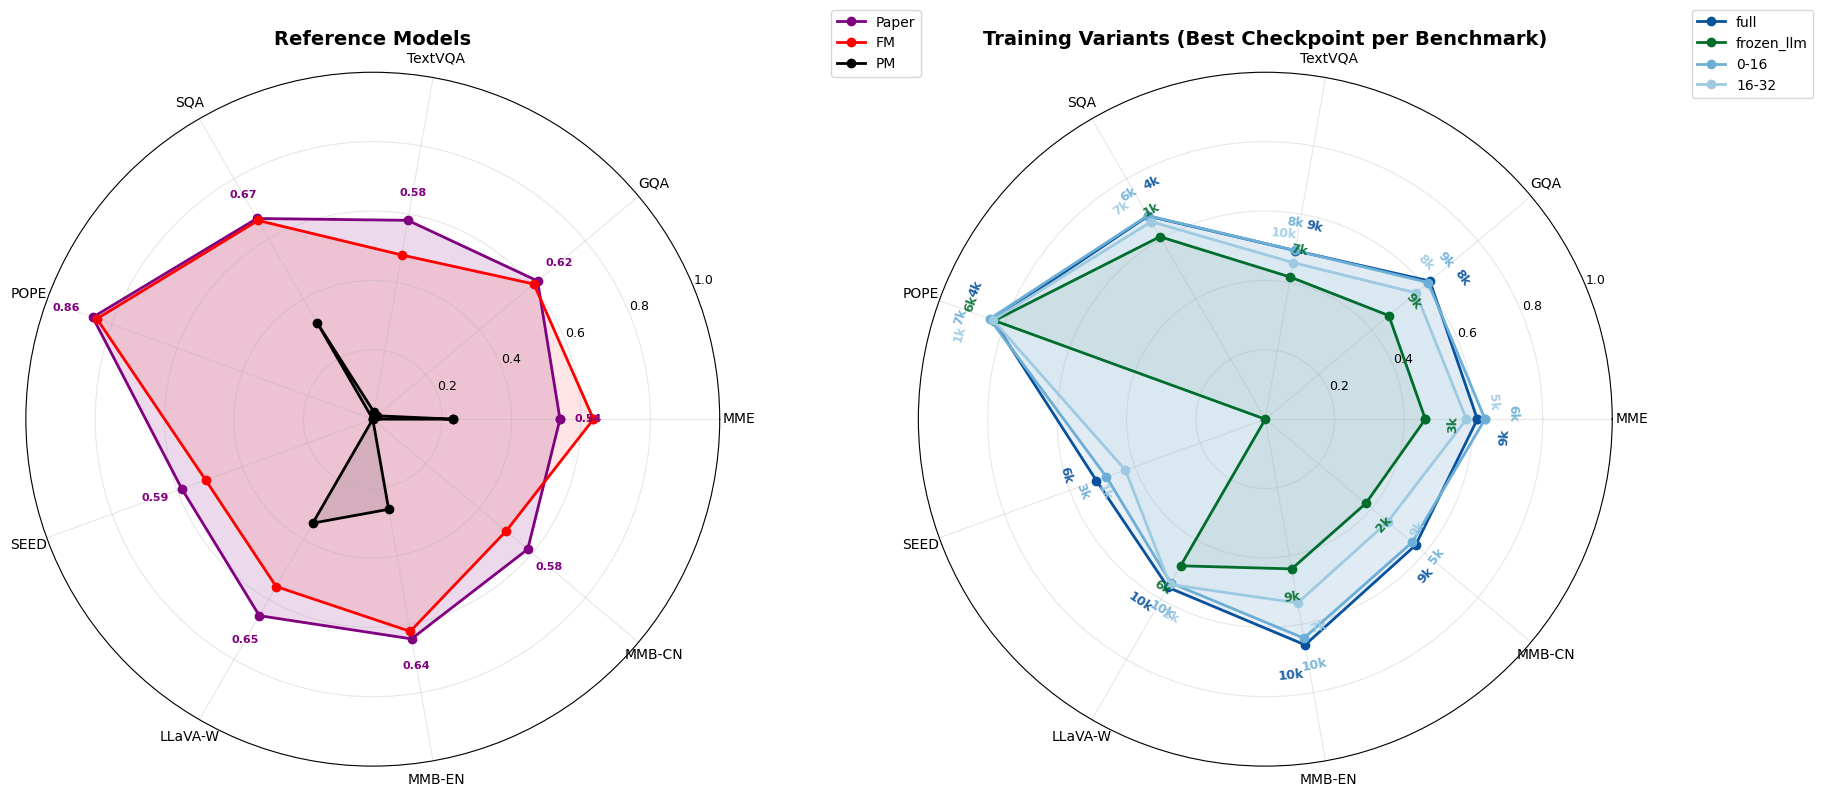

In [12]:
def create_radar_plot():
    """Create side-by-side radar plots comparing models across benchmarks"""
    
    # Setup
    categories = list(BENCHMARKS.keys())
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # Complete the circle
    
    # Create figure with 2 subplots
    fig, axes = plt.subplots(1, 2, figsize=(18, 8), subplot_kw=dict(projection='polar'))
    
    # ============ LEFT PLOT: REFERENCE (Paper + FM + PM) ============
    ax = axes[0]
    
    # Paper reference
    values = [REFERENCE_NORMALIZED[cat] for cat in categories]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label='Paper', color='purple', markersize=6)
    ax.fill(angles, values, alpha=0.15, color='purple')
    
    # Add value labels for paper reference
    for angle, value, cat in zip(angles[:-1], values[:-1], categories):
        ax.text(angle, value + 0.08, f'{value:.2f}', ha='center', va='center', 
                fontsize=8, color='purple', weight='bold')
    
    # Finetuned
    if 'finetuned' in model_max_scores:
        fm_values = [model_max_scores['finetuned'].get(cat, {}).get('score', 0) for cat in categories]
        fm_values += fm_values[:1]
        ax.plot(angles, fm_values, 'o-', linewidth=2, label='FM', color=COLOR_SCHEME['FM'], markersize=6)
        ax.fill(angles, fm_values, alpha=0.1, color=COLOR_SCHEME['FM'])
    
    # Pretrained
    if 'pretrained' in model_max_scores:
        pm_values = [model_max_scores['pretrained'].get(cat, {}).get('score', 0) for cat in categories]
        pm_values += pm_values[:1]
        ax.plot(angles, pm_values, 'o-', linewidth=2, label='PM', color=COLOR_SCHEME['PM'], markersize=6)
        ax.fill(angles, pm_values, alpha=0.1, color=COLOR_SCHEME['PM'])
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([BENCHMARKS[cat]['abbrev'] for cat in categories], fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)
    ax.set_title('Reference Models', size=14, weight='bold', pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # ============ RIGHT PLOT: TRAINING VARIANTS ============
    ax = axes[1]
    
    # Plot each training variant and collect checkpoint info
    training_models = ['Llava1.5-7B', 'Llava1.5-7B-frozen', 'Llava1.5-7B-0-16', 'Llava1.5-7B-16-32']
    
    # Calculate angular offsets for tangential separation
    n_models = len(training_models)
    total_spread = 0.15  # Total angular spread in radians
    model_offsets = np.linspace(-total_spread/2, total_spread/2, n_models)
    
    for m_idx, model in enumerate(training_models):
        if model in model_max_scores:
            label = NAMES_MAPPING.get(model, model)
            color = COLOR_SCHEME.get(label, '#000000')
            
            values = []
            steps = []
            for cat in categories:
                if cat in model_max_scores[model]:
                    values.append(model_max_scores[model][cat]['score'])
                    steps.append(model_max_scores[model][cat]['step'])
                else:
                    values.append(0)
                    steps.append(0)
            
            values += values[:1]
            ax.plot(angles, values, 'o-', linewidth=2, label=label, color=color, markersize=6)
            ax.fill(angles, values, alpha=0.08, color=color)
            
            # Add checkpoint labels with tangential separation
            for i, (angle, value, step) in enumerate(zip(angles[:-1], values[:-1], steps)):
                if step > 0 and value > 0:
                    # Apply model-specific angular offset
                    label_angle = angle + model_offsets[m_idx]
                    
                    # Calculate rotation for tangential alignment based on NEW angle
                    angle_deg = np.degrees(label_angle)
                    if 0 <= angle_deg <= 180:
                        rotation = angle_deg - 90
                    else:
                        rotation = angle_deg + 90
                    
                    # Fixed radial offset
                    label_radius = value + 0.08
                    
                    ax.text(label_angle, label_radius, f'{step//1000}k', 
                           ha='center', va='center', fontsize=9, 
                           color=color, weight='bold', alpha=0.9, 
                           rotation=rotation, rotation_mode='anchor')
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([BENCHMARKS[cat]['abbrev'] for cat in categories], fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)
    ax.set_title('Training Variants (Best Checkpoint per Benchmark)', size=14, weight='bold', pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Create the radar plot
create_radar_plot()

In [13]:
import pandas as pd

# Create checkpoint information table
def display_checkpoint_table():
    """Display clean table showing which checkpoint achieved max score for each model/benchmark"""
    
    training_models = ['Llava1.5-7B', 'Llava1.5-7B-frozen', 'Llava1.5-7B-0-16', 'Llava1.5-7B-16-32']
    categories = list(BENCHMARKS.keys())
    
    # Build data for table
    table_data = []
    for model in training_models:
        if model in model_max_scores:
            row = {'Model': NAMES_MAPPING.get(model, model)}
            for cat in categories:
                if cat in model_max_scores[model]:
                    step = model_max_scores[model][cat]['step']
                    score = model_max_scores[model][cat]['score']
                    # Format: "step (score)"
                    if isinstance(step, int):
                        row[BENCHMARKS[cat]['abbrev']] = f"{step//1000}k"
                    else:
                        row[BENCHMARKS[cat]['abbrev']] = "-"
                else:
                    row[BENCHMARKS[cat]['abbrev']] = "-"
            table_data.append(row)
    
    df = pd.DataFrame(table_data)
    df = df.set_index('Model')
    
    print("\n" + "="*80)
    print("CHECKPOINT TABLE: Training step (in thousands) where max score was achieved")
    print("="*80)
    print(df.to_string())
    print("="*80)
    print("Example: '7k' means the model achieved its best score at training step 7000")
    print("="*80 + "\n")
    
    return df

# Display the checkpoint table
checkpoint_df = display_checkpoint_table()


CHECKPOINT TABLE: Training step (in thousands) where max score was achieved
           MME GQA TextVQA SQA POPE SEED LLaVA-W MMB-EN MMB-CN
Model                                                         
full        9k  8k      9k  4k   4k   6k     10k    10k     9k
frozen_llm  3k  9k      7k  1k   6k    -      6k     9k     2k
0-16        6k  9k      8k  6k   7k   3k     10k    10k     5k
16-32       5k  8k     10k  7k   1k   1k      2k     7k     9k
Example: '7k' means the model achieved its best score at training step 7000

